# 1

### Nota: 7.9

El objetivo de este ejercicio es desarrollar un modelo de regresión supervisada utilizando Python y el dataset "Housing.csv". El dataset contiene información sobre precios de viviendas y varias características relevantes. El reto consiste en predecir la columna "price" utilizando técnicas de machine learning supervisado y el paquete scikit-learn. En este reto, se trabajará con variables categóricas y numéricas, para lo cual será necesario preprocesar los datos adecuadamente. ¡Suerte con el reto!

In [68]:
import pandas as pd
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt

work_dir = "../media/1_lab4/1/"
file_dir = "Housing.csv"

df = pd.read_csv(work_dir + file_dir)

In [69]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Veamos las columnas que hay, y su tipo de dato.

In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


Observemos valores nulos

In [71]:
df.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

No hay valores nulos.

Hagamos un histograma de la variable price.

Text(0.5, 1.0, 'Histograma de precios')

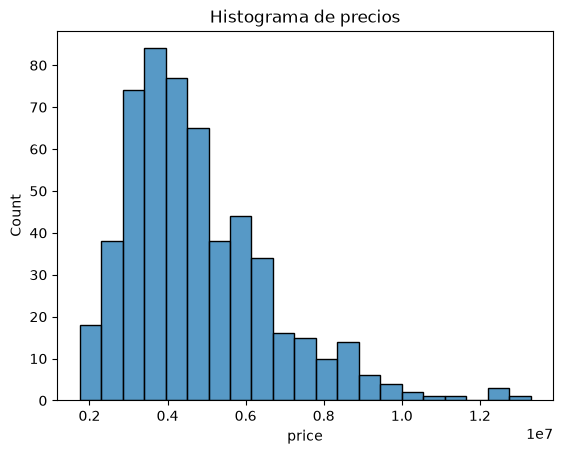

In [72]:
sns.histplot(data = df, x = "price")
plt.title("Histograma de precios")

A primera vista no parece que hayan valores atípicos, veamos el boxplot.

<Axes: xlabel='price'>

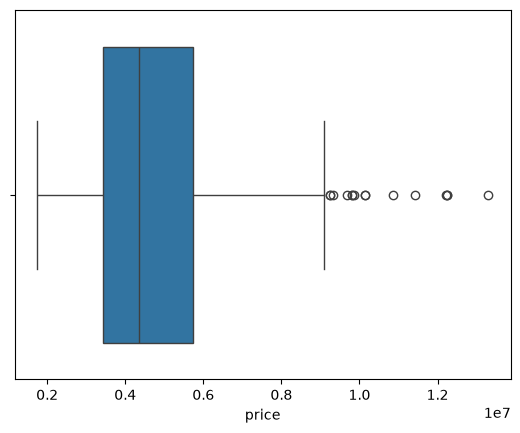

In [73]:
sns.boxplot(data = df, x = "price")

Parecen haber outliers, pero al ser un data set pequeño, y no ser una gran cantidad, vamos a dejarlos donde están. Hagamos un pairplot para una visión más general.

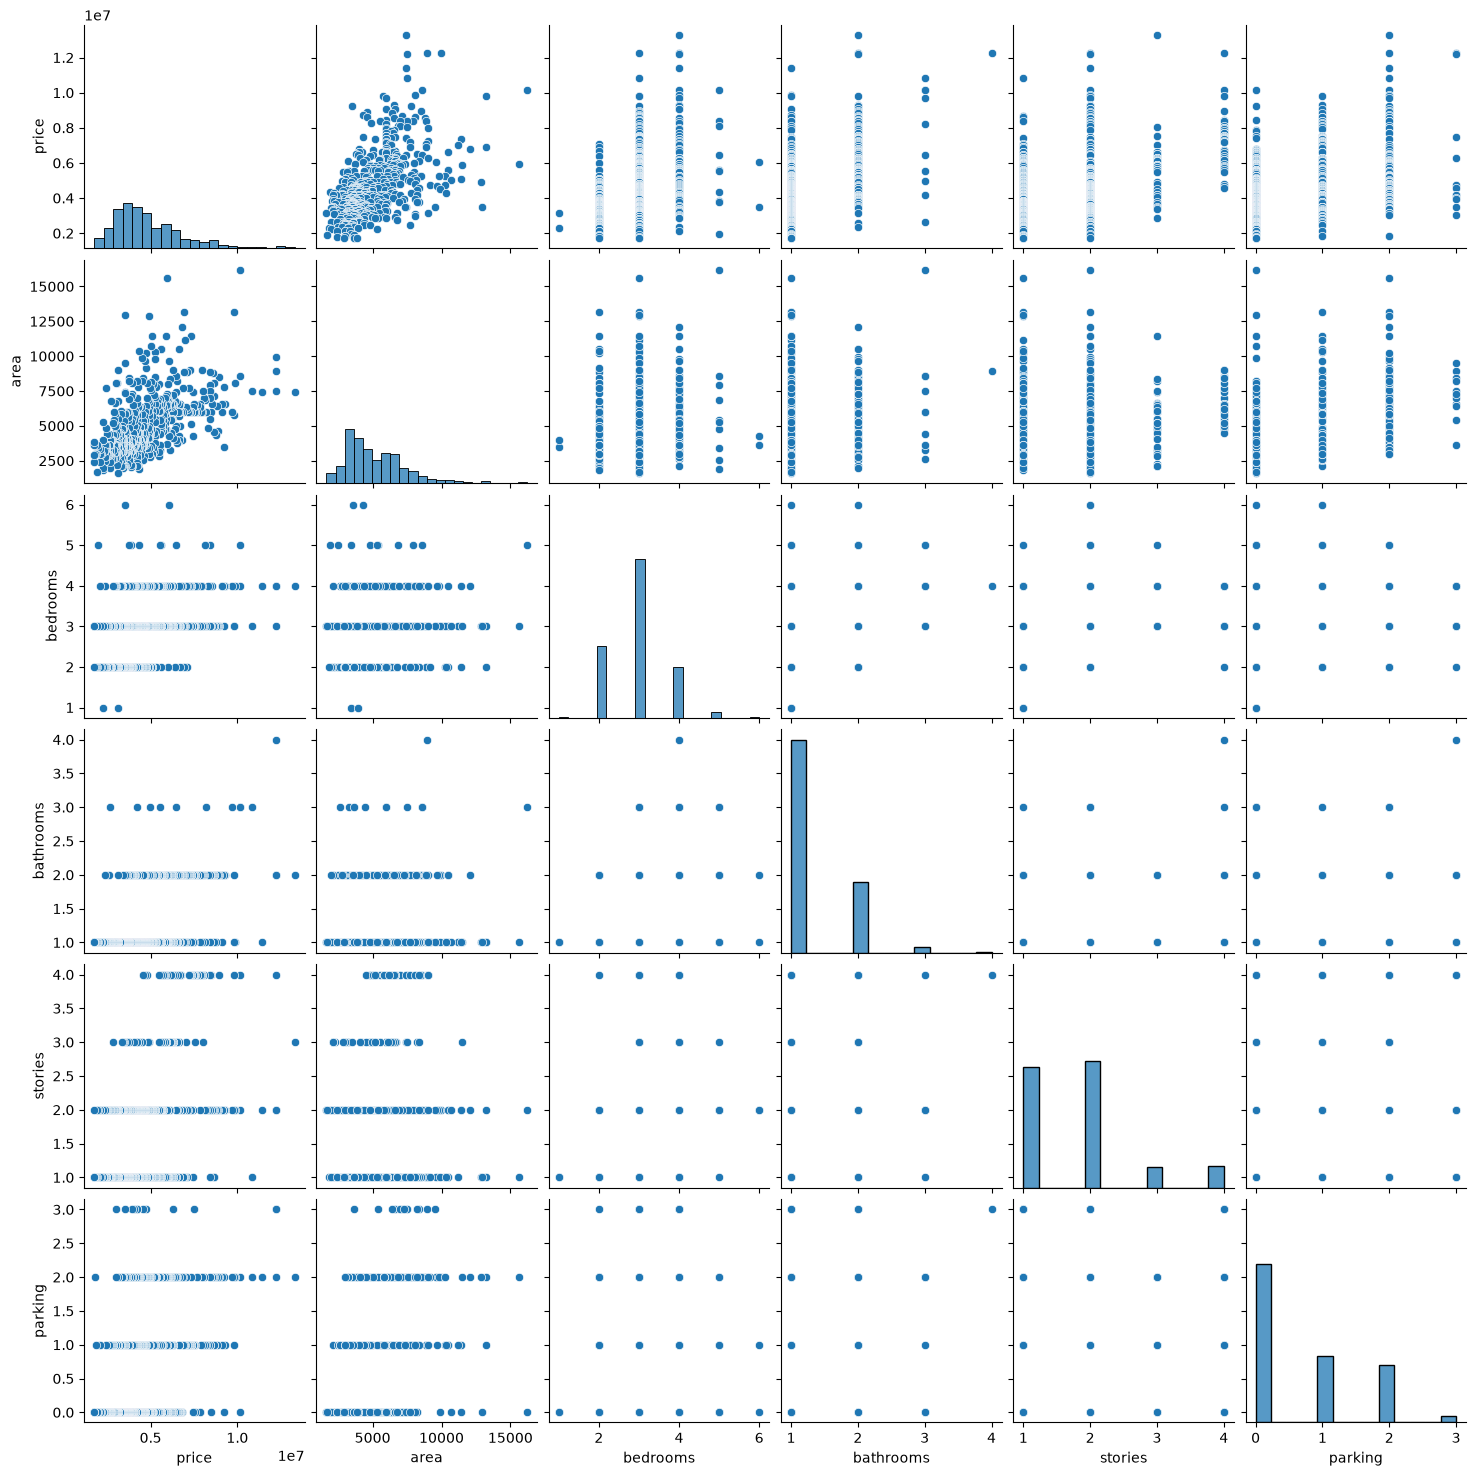

In [74]:
sns.pairplot(data = df)

Vimos antes que habían varias variables categóricas. Las binarias, las vamos a mapear a 0 y 1, mientras que a furnishingstatus le haremos un one hot encoding.

In [75]:
def binary(x):
    return x.map({"yes": 1, "no": 0})

binary_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
df[binary_cols] = df[binary_cols].apply(binary)
furn = pd.get_dummies(df["furnishingstatus"], dtype = int)
df.drop("furnishingstatus", axis = 1, inplace = True)
df = pd.concat([df, furn], axis = 1)

/tmp/ipykernel_6569/848803834.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop("furnishingstatus", axis = 1, inplace = True)


In [76]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnished,semi-furnished,unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1,0,0


In [77]:
df.describe()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnished,semi-furnished,unfurnished
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.858716,0.177982,0.350459,0.045872,0.315596,0.693578,0.234862,0.256881,0.416514,0.326606
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.348635,0.382849,0.477552,0.209399,0.465180,0.861586,0.424302,0.437314,0.493434,0.469402
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000


En el caso de area vamos a normalizar (distribuciones ligeramente sesgadas), y en el resto (menos las categóricas) estandraizamos.

In [ ]:
normalize_minmax = lambda x: (x - x.min()) / (x.max() - x.min())
standarize = lambda x: (x - x.mean()) / x.std()

norm_cols = ["area"]
stand_cols = ["bedrooms", "bathrooms", "stories"]

df[norm_cols] = df[norm_cols].apply(normalize_minmax)
df[stand_cols] = df[stand_cols].apply(standarize)

In [79]:
df.describe()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnished,semi-furnished,unfurnished
count,545.000000,545.000000,5.450000e+02,545.000000,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000
mean,0.261189,0.240587,-2.085997e-16,0.000000,-1.303748e-16,0.858716,0.177982,0.350459,0.045872,0.315596,0.693578,0.234862,0.256881,0.416514,0.326606
std,0.161943,0.149151,1.000000e+00,1.000000,1.000000e+00,0.348635,0.382849,0.477552,0.209399,0.465180,0.861586,0.424302,0.437314,0.493434,0.469402
min,0.000000,0.000000,-2.662558e+00,-0.569663,-9.285436e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.145455,0.134021,-1.307661e+00,-0.569663,-9.285436e-01,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.224242,0.202749,4.723492e-02,-0.569663,2.242042e-01,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.345455,0.323711,4.723492e-02,1.420507,2.242042e-01,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,4.111924e+00,5.400847,2.529700e+00,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000


Mapa de calor para correlación

<Axes: >

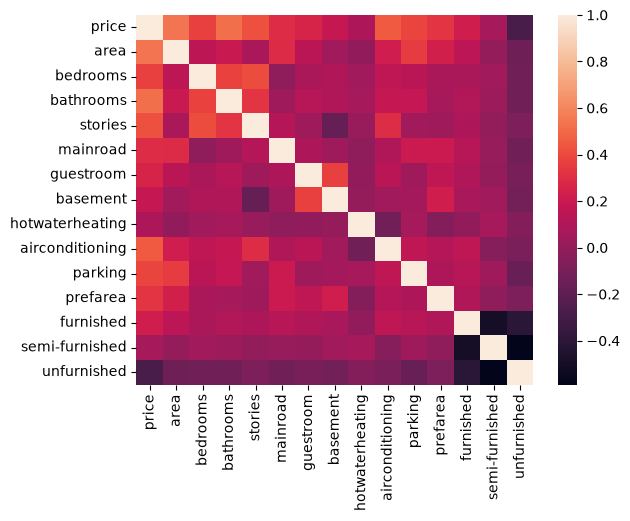

In [80]:
corr = df.corr()
sns.heatmap(corr)

Dividimos en conjuntos de train y de test.

In [82]:
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(df.drop(columns = "price"), df["price"],
                                                                       test_size = 0.2)

Creamos el modelo de regresión lineal y lo entrenamos.

In [83]:
lm = sk.linear_model.LinearRegression()
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[ 0.3 , 0.01, 0.05,..., 0.01, 0.01,-0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['area','bedrooms','bathrooms',...,'furnished','semi-furnished', 'unfurnished']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.08905
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


Obtenemos los coeficientes y el intercepto.

In [84]:
print(f"Coeficientes del modelo: {lm.coef_}")
print(f"Intercepto del modelo: {lm.intercept_}")

Coeficientes del modelo: [ 0.29850532  0.00788178  0.04806662  0.03258189  0.0396332   0.02939006
  0.02167811  0.0796675   0.06215052  0.02274258  0.0573062   0.01329429
  0.00837699 -0.02167127]
Intercepto del modelo: 0.08905216262259488


Hay un coeficiente por cada predictor, y se entiende como lo que aporta esa variable a la predicción del target. El intercepto es simplemente la ordenada en el origen.

Evaluemos el modelo usando distintas métricas.

In [ ]:
preds = lm.predict(X_test)

r2 = sk.metrics.r2_score(y_test, preds)
mae = sk.metrics.mean_absolute_error(y_test, preds)
mse = sk.metrics.mean_squared_error(y_test, preds)

print(f"R2: {r2}")
print(f"MAE: {mae}")
print(f"MSE: {mse}")

R2: 0.5993749965666311
MAE: 0.07628839127179872
RMSE: 0.1043132000678259


A pesar de que el R2 no es el mejor, tenemos un dataset pequeño, y el MAE y MSE dan resultados razonables, por lo que el modelo se queda así, comparemos valores predichos por reales.

Text(0, 0.5, 'Valores reales')

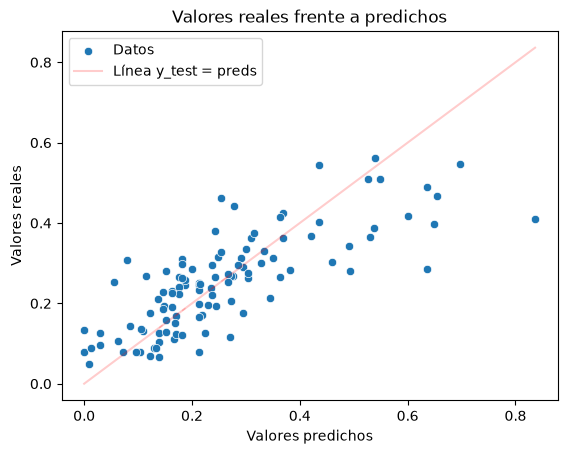

In [ ]:
sns.scatterplot(x = y_test, y = preds, label = "Datos")
sns.lineplot(x = y_test, y = y_test, label = "Línea y_test = preds", c = "r", alpha = 0.2)
plt.title("Valores predichos frente a reales")
plt.ylabel("Valores predichos")
plt.xlabel("Valores reales")

Vemos que las predicciones son bastante decentes. La distribución de errores residuales:

/tmp/ipykernel_6569/1697390458.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res)


<Axes: xlabel='price', ylabel='Density'>

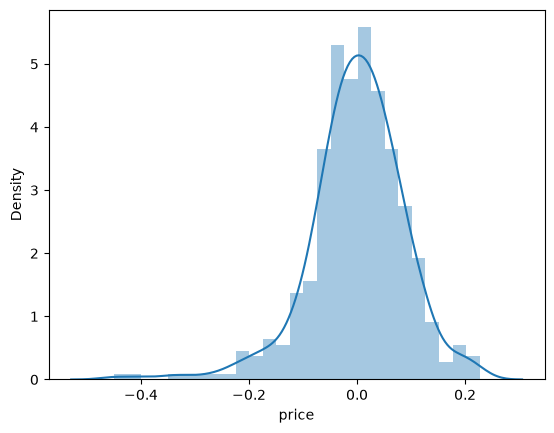

In [ ]:
res = preds - y_test
sns.distplot(res)

Vemos que siguen una distribución normal centrada en 0.